# 01 EDA: Telecom churn (Step 3)

Rules: anything that looks at the target uses the **training split only** (`data/processed/train.csv`).
Only the structure checks in 3.1 use the full cleaned file (`data/interim/churn.csv`). The held-out test file is never read.
Numbers quoted in `docs/development_strategy.md` are hypotheses; each is re-checked on train below. No production logic lives here.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import proportion_confint

from churn.data import read_typed_csv

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = Path(os.environ.get("CHURN_DATA_DIR", ROOT / "data"))
TARGET = "class"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 70, "savefig.dpi": 70, "figure.max_open_warning": 0})
pd.set_option("display.width", 140)

full = read_typed_csv(DATA / "interim" / "churn.csv")
train = read_typed_csv(DATA / "processed" / "train.csv")
CATS = ["state", "area_code"]
BINS = ["international_plan", "voice_mail_plan"]
USAGE = [c for c in train.columns if c.startswith("total_")]
NUM = [c for c in train.columns if c not in CATS + BINS + [TARGET]]
print(full.shape, train.shape)

(5000, 20) (4000, 20)


## 3.1 Data quality (full cleaned file)

In [2]:
print("shape:", full.shape)
print("missing values:", int(full.isna().sum().sum()))
print("duplicate rows:", int(full.duplicated().sum()))
print("churn rate (full):", round(full[TARGET].mean(), 4))
display(full.dtypes.to_frame("dtype").T)

shape: (5000, 20)
missing values: 0
duplicate rows: 0
churn rate (full): 0.1414


,state,account_length,area_code,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,class
dtype,category,int64,category,int64,int64,int64,float64,int64,float64,float64,int64,float64,float64,int64,float64,float64,int64,float64,int64,int64


In [3]:
num_cols = [c for c in full.columns if c not in CATS]
ranges = full[num_cols].agg(["min", "max"]).T
print("negative values in any numeric column:", int((full[num_cols] < 0).sum().sum()))
print("service calls range:", full["number_customer_service_calls"].agg(["min", "max"]).tolist())
print("account_length min:", full["account_length"].min())
display(ranges)

negative values in any numeric column: 0
service calls range: [0, 9]
account_length min: 1


,min,max
account_length,1.0,243.00
international_plan,0.0,1.00
voice_mail_plan,0.0,1.00
number_vmail_messages,0.0,52.00
total_day_minutes,0.0,351.50
total_day_calls,0.0,165.00
total_day_charge,0.0,59.76
total_eve_minutes,0.0,363.70
total_eve_calls,0.0,170.00
total_eve_charge,0.0,30.91


In [4]:
# voice_mail_plan == 1 exactly when vmail messages > 0 (one known exception expected)
mismatch = full[(full["voice_mail_plan"] == 1) != (full["number_vmail_messages"] > 0)]
print("voicemail flag vs messages mismatches:", len(mismatch))
display(mismatch[["voice_mail_plan", "number_vmail_messages", TARGET]])

# charge = rate x minutes in every period
for p in ["day", "eve", "night", "intl"]:
    rate = full[f"total_{p}_charge"] / full[f"total_{p}_minutes"].replace(0, np.nan)
    print(
        f"{p:5s} rate/min: median={rate.median():.4f}  min={rate.min():.4f}  max={rate.max():.4f}"
    )
print("phone_number uniqueness was verified at ingestion (column already dropped).")

voicemail flag vs messages mismatches: 1


,voice_mail_plan,number_vmail_messages,class
4902,1,0,0


day   rate/min: median=0.1700  min=0.1692  max=0.1705
eve   rate/min: median=0.0850  min=0.0849  max=0.0852
night rate/min: median=0.0450  min=0.0448  max=0.0451
intl  rate/min: median=0.2700  min=0.2682  max=0.2750
phone_number uniqueness was verified at ingestion (column already dropped).


**Reading 3.1.** Check the counts above: no missing values, no duplicates, all ranges valid. The charge columns are a fixed rate
times minutes in each period (rate spread is rounding only), so they carry no extra information.

## 3.2 Univariate (train)

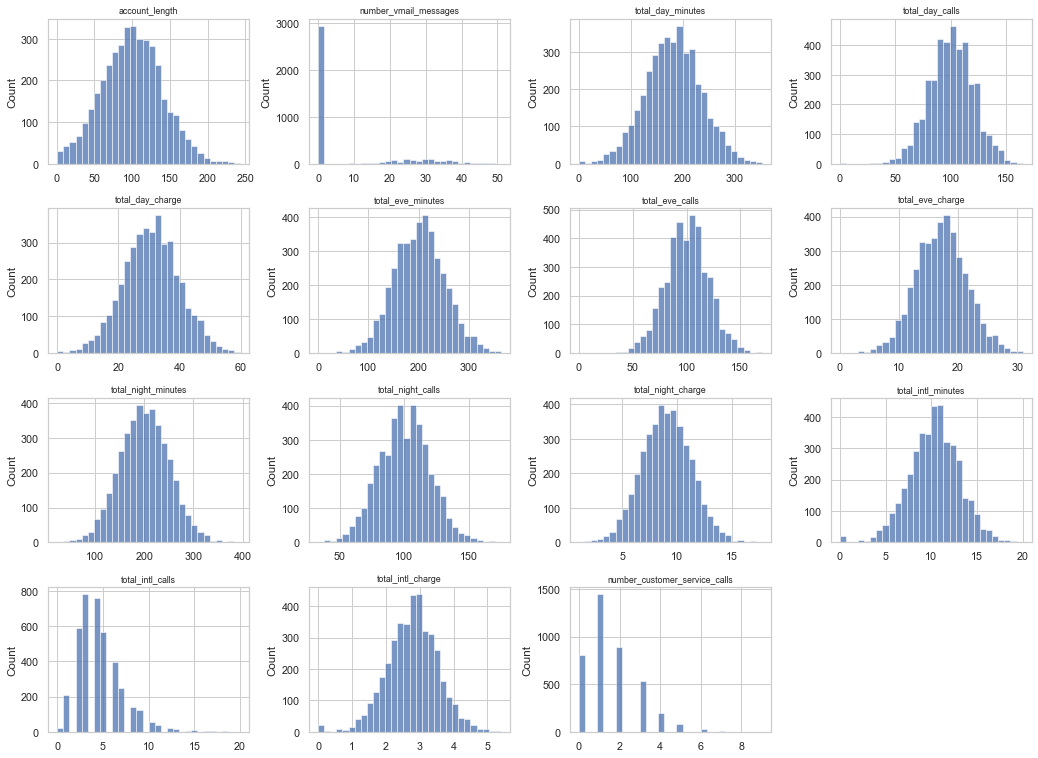

share of zero vmail messages: 0.735


,mean,std,min,50%,max
account_length,99.98,39.87,1.00,100.00,243.00
number_vmail_messages,7.74,13.51,0.00,0.00,51.00
total_day_minutes,180.57,53.80,0.00,180.50,351.50
total_day_calls,100.26,19.91,0.00,100.00,165.00
total_day_charge,30.70,9.15,0.00,30.69,59.76
total_eve_minutes,201.01,50.35,0.00,201.40,363.70
total_eve_calls,100.07,19.88,0.00,100.00,170.00
total_eve_charge,17.09,4.28,0.00,17.12,30.91
total_night_minutes,200.48,50.18,23.20,200.35,395.00
total_night_calls,99.89,19.85,33.00,100.00,175.00


In [5]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for ax, c in zip(axes.ravel(), NUM, strict=False):
    sns.histplot(train[c], bins=30, ax=ax, color="#4c72b0")
    ax.set_title(c, fontsize=9)
    ax.set_xlabel("")
for ax in axes.ravel()[len(NUM) :]:
    ax.axis("off")
fig.tight_layout()
plt.show()
print("share of zero vmail messages:", round((train["number_vmail_messages"] == 0).mean(), 3))
display(train[NUM].describe().T[["mean", "std", "min", "50%", "max"]].round(2))

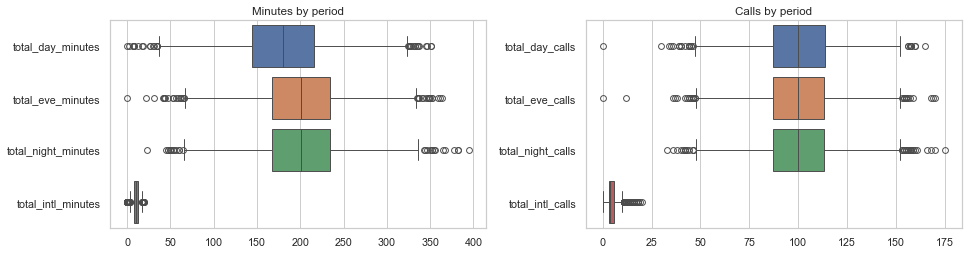

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
sns.boxplot(data=train[[c for c in USAGE if c.endswith("minutes")]], orient="h", ax=axes[0])
axes[0].set_title("Minutes by period")
sns.boxplot(data=train[[c for c in USAGE if c.endswith("calls")]], orient="h", ax=axes[1])
axes[1].set_title("Calls by period")
fig.tight_layout()
plt.show()

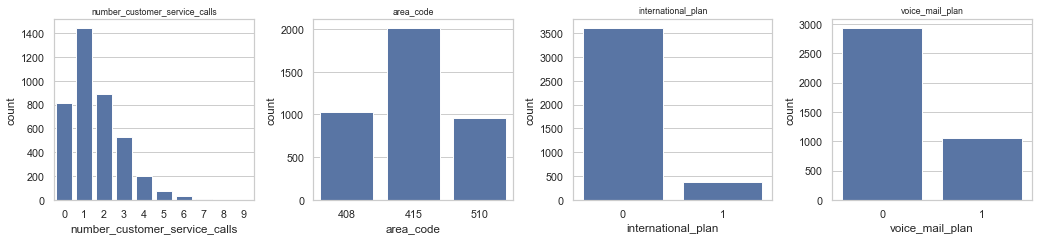

state customers per level: min 41 median 78 max 122
states with fewer than 60 training customers: 4 of 51


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, c in zip(
    axes,
    ["number_customer_service_calls", "area_code", "international_plan", "voice_mail_plan"],
    strict=False,
):
    sns.countplot(x=train[c], ax=ax, color="#4c72b0")
    ax.set_title(c, fontsize=9)
fig.tight_layout()
plt.show()

state_n = train["state"].value_counts()
print(
    "state customers per level: min",
    state_n.min(),
    "median",
    int(state_n.median()),
    "max",
    state_n.max(),
)
print(
    "states with fewer than 60 training customers:", int((state_n < 60).sum()), "of", len(state_n)
)

## 3.3 Target analysis (train)

In [8]:
base = train[TARGET].mean()
print(f"churners: {train[TARGET].sum()} of {len(train)}  churn rate {base:.4f}")
print(f"No-skill PR-AUC baseline = churn rate = {base:.3f}")

churners: 566 of 4000  churn rate 0.1415
No-skill PR-AUC baseline = churn rate = 0.141


In [9]:
def rate_table(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """Churn rate per level with Wilson 95% CI."""
    g = df.groupby(col, observed=True)[TARGET].agg(["size", "sum"])
    g.columns = ["n", "churned"]
    lo, hi = proportion_confint(g["churned"], g["n"], method="wilson")
    g["rate"] = g["churned"] / g["n"]
    g["ci_low"], g["ci_high"] = lo, hi
    return g


def chi2_p(df: pd.DataFrame, col: str) -> tuple[float, float]:
    """Chi-square statistic and p-value of col vs target."""
    ct = pd.crosstab(df[col], df[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    return chi2, p


def plot_rate(tab: pd.DataFrame, ax, title: str) -> None:
    x = np.arange(len(tab))
    ax.bar(x, tab["rate"], color="#4c72b0")
    ax.errorbar(
        x,
        tab["rate"],
        yerr=[tab["rate"] - tab["ci_low"], tab["ci_high"] - tab["rate"]],
        fmt="none",
        ecolor="black",
        capsize=3,
    )
    ax.axhline(base, ls="--", color="grey")
    ax.set_xticks(
        x, [f"{i}\n(n={n})" for i, n in zip(tab.index, tab["n"], strict=True)], fontsize=8
    )
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("churn rate")

,feature,chi2,p_value
0,international_plan,272.7,2.97e-61
1,voice_mail_plan,52.7,3.93e-13
2,area_code,0.4,8.13e-01
3,state,96.5,8.78e-05
4,number_customer_service_calls,389.1,2.86e-78


,n,churned,rate,ci_low,ci_high
international_plan,,,,,
0,3620,405,0.112,0.102,0.123
1,380,161,0.424,0.375,0.474


,n,churned,rate,ci_low,ci_high
voice_mail_plan,,,,,
0,2939,487,0.166,0.153,0.180
1,1061,79,0.074,0.060,0.092


,n,churned,rate,ci_low,ci_high
area_code,,,,,
408,1024,139,0.136,0.116,0.158
415,2016,291,0.144,0.130,0.160
510,960,136,0.142,0.121,0.165


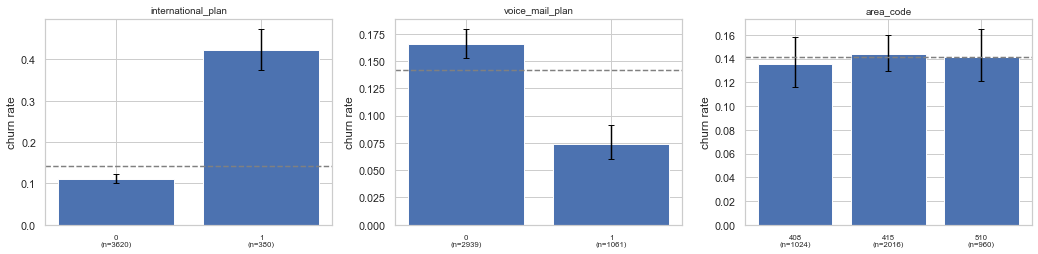

In [10]:
rows = []
for c in BINS + ["area_code", "state", "number_customer_service_calls"]:
    chi2, p = chi2_p(train, c)
    rows.append({"feature": c, "chi2": round(chi2, 1), "p_value": f"{p:.2e}"})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axes, BINS + ["area_code"], strict=False):
    tab = rate_table(train, c)
    plot_rate(tab, ax, c)
    display(tab.round(3))
fig.tight_layout()
plt.show()

,n,churned,rate,ci_low,ci_high
number_customer_service_calls,,,,,
0,811,93,0.115,0.095,0.138
1,1448,160,0.110,0.095,0.128
2,893,98,0.110,0.091,0.132
3,530,56,0.106,0.082,0.135
4,199,87,0.437,0.370,0.507
5,77,44,0.571,0.460,0.676
6,28,19,0.679,0.493,0.821
7,11,6,0.545,0.280,0.787
8,1,1,1.000,0.207,1.000


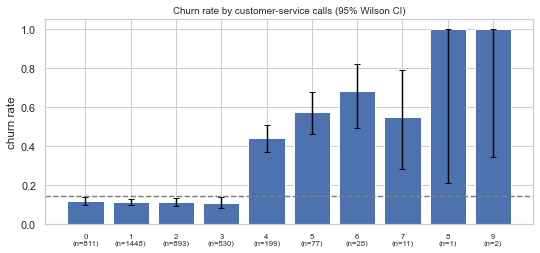

0-3 calls: 0.111 (n=3682)   4+ calls: 0.500 (n=318)


In [11]:
sc = rate_table(train, "number_customer_service_calls")
display(sc.round(3))
fig, ax = plt.subplots(figsize=(9, 3.8))
plot_rate(sc, ax, "Churn rate by customer-service calls (95% Wilson CI)")
plt.show()
low = train[train["number_customer_service_calls"] <= 3][TARGET]
high = train[train["number_customer_service_calls"] >= 4][TARGET]
print(f"0-3 calls: {low.mean():.3f} (n={len(low)})   4+ calls: {high.mean():.3f} (n={len(high)})")

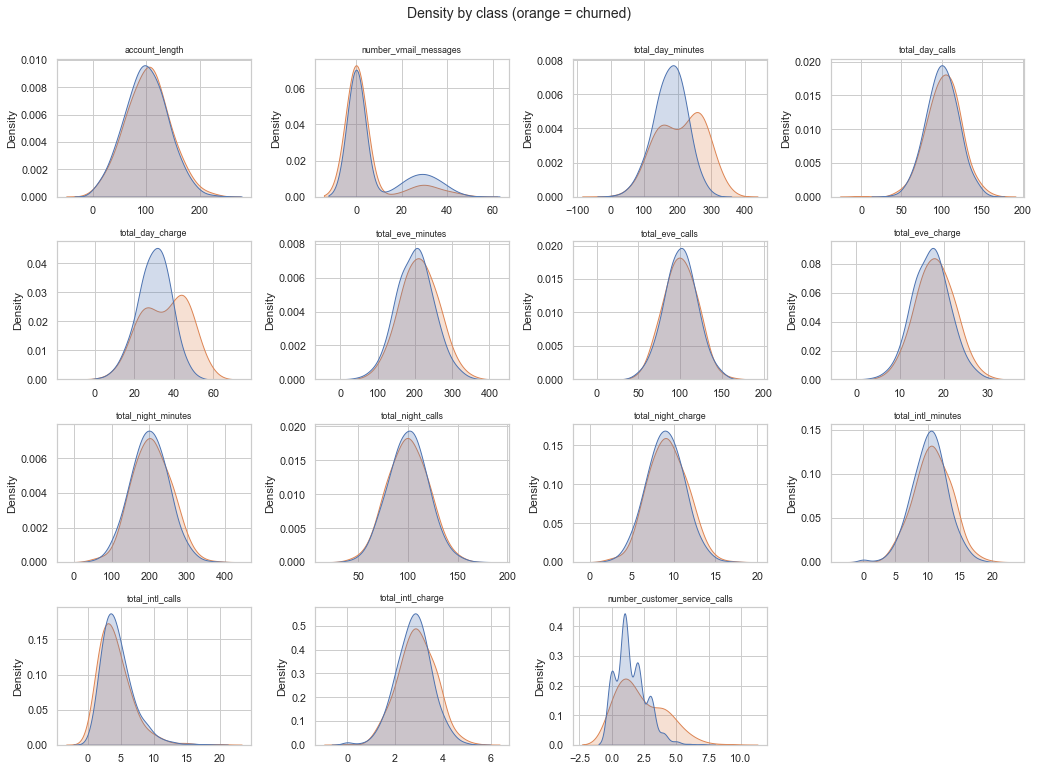

,feature,mean_churn,mean_stay,auc_like,p_value
2,total_day_minutes,208.6046,175.9475,0.6429,0.0000
4,total_day_charge,35.4632,29.9117,0.6429,0.0000
14,number_customer_service_calls,2.2509,1.4566,0.6135,0.0000
1,number_vmail_messages,4.3551,8.2976,0.4298,0.0000
5,total_eve_minutes,211.0242,199.3614,0.5647,0.0000
7,total_eve_charge,17.9373,16.9460,0.5647,0.0000
12,total_intl_calls,4.1926,4.5140,0.4497,0.0001
11,total_intl_minutes,10.7299,10.2174,0.5501,0.0001


In [12]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for ax, c in zip(axes.ravel(), NUM, strict=False):
    sns.kdeplot(
        data=train,
        x=c,
        hue=TARGET,
        common_norm=False,
        fill=True,
        ax=ax,
        legend=False,
        bw_adjust=1.5,
        warn_singular=False,
    )
    ax.set_title(c, fontsize=9)
    ax.set_xlabel("")
for ax in axes.ravel()[len(NUM) :]:
    ax.axis("off")
fig.suptitle("Density by class (orange = churned)", y=1.0)
fig.tight_layout()
plt.show()

# Mann-Whitney effect: which numerics differ most between classes
rows = []
for c in NUM:
    a, b = train.loc[train[TARGET] == 1, c], train.loc[train[TARGET] == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    rows.append(
        {
            "feature": c,
            "mean_churn": a.mean(),
            "mean_stay": b.mean(),
            "auc_like": u / (len(a) * len(b)),
            "p_value": p,
        }
    )
display(pd.DataFrame(rows).sort_values("p_value").round(4).head(8))

## 3.4 Relationships and redundancy (train)

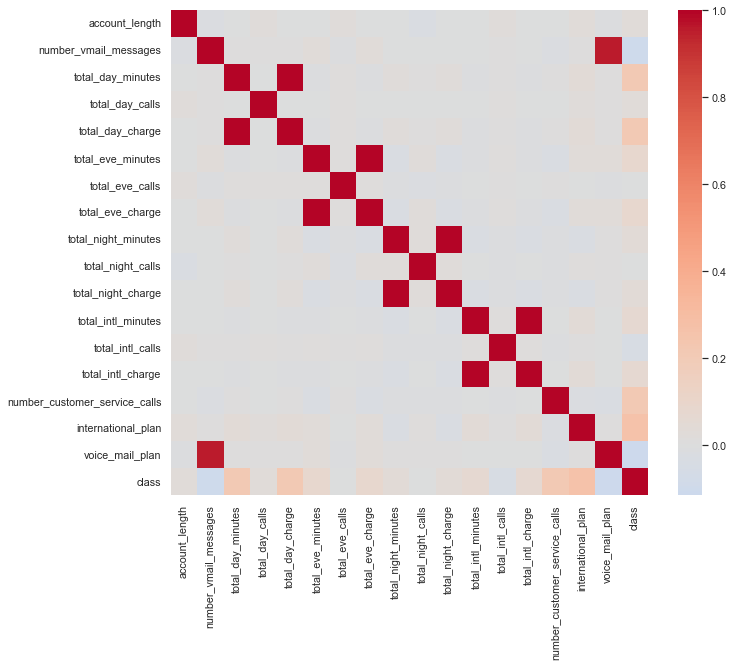

Correlation of each charge with its minutes column:
  day   r = 1.000000
  eve   r = 1.000000
  night r = 0.999999
  intl  r = 0.999993

Correlation with target:


,class
international_plan,0.262
number_customer_service_calls,0.212
total_day_minutes,0.212
total_day_charge,0.212
voice_mail_plan,-0.116
number_vmail_messages,-0.102
total_eve_minutes,0.081
total_eve_charge,0.081
total_intl_minutes,0.065
total_intl_charge,0.065


In [13]:
corr = train[NUM + BINS + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, ax=ax)
plt.show()
print("Correlation of each charge with its minutes column:")
for p in ["day", "eve", "night", "intl"]:
    r = train[f"total_{p}_charge"].corr(train[f"total_{p}_minutes"])
    print(f"  {p:5s} r = {r:.6f}")
print("\nCorrelation with target:")
display(
    corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).head(10).to_frame()
)

In [14]:
X = train[NUM + BINS].astype(float)
X = (X - X.mean()) / X.std()
vif = pd.Series(
    [variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns
)
print("VIF with all columns (charge/minutes pairs explode):")
display(vif.sort_values(ascending=False).round(1).head(10).to_frame("VIF"))

keep = [c for c in X.columns if not c.endswith("_charge")]
Xk = X[keep]
vif2 = pd.Series(
    [variance_inflation_factor(Xk.values, i) for i in range(Xk.shape[1])], index=Xk.columns
)
print("VIF after dropping the four *_charge columns: max =", round(vif2.max(), 2))
display(vif2.sort_values(ascending=False).round(2).head(5).to_frame("VIF"))

VIF with all columns (charge/minutes pairs explode):


,VIF
total_day_charge,10276616.8
total_day_minutes,10276613.4
total_eve_charge,2203696.7
total_eve_minutes,2203693.5
total_night_minutes,627945.8
total_night_charge,627944.0
total_intl_minutes,67926.8
total_intl_charge,67926.7
voice_mail_plan,11.1
number_vmail_messages,11.1


VIF after dropping the four *_charge columns: max = 11.14


,VIF
voice_mail_plan,11.14
number_vmail_messages,11.14
international_plan,1.01
total_eve_minutes,1.00
account_length,1.00


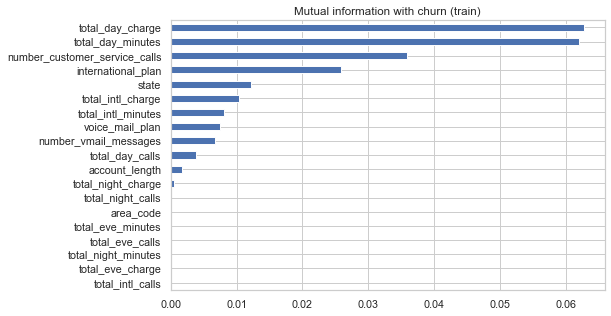

,MI
total_day_charge,0.0628
total_day_minutes,0.0619
number_customer_service_calls,0.0360
international_plan,0.0258
state,0.0122
total_intl_charge,0.0103
total_intl_minutes,0.0081
voice_mail_plan,0.0075


Note: MI on 4,000 rows is noisy, especially for the many-level state.


In [15]:
feats = train.drop(columns=[TARGET]).copy()
for c in CATS:
    feats[c] = feats[c].cat.codes
discrete = [feats.columns.get_loc(c) for c in CATS + BINS]
mi = pd.Series(
    mutual_info_classif(feats, train[TARGET], discrete_features=discrete, random_state=0),
    index=feats.columns,
).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
mi.plot.barh(ax=ax, color="#4c72b0")
ax.invert_yaxis()
ax.set_title("Mutual information with churn (train)")
plt.show()
display(mi.round(4).head(8).to_frame("MI"))
print("Note: MI on 4,000 rows is noisy, especially for the many-level state.")

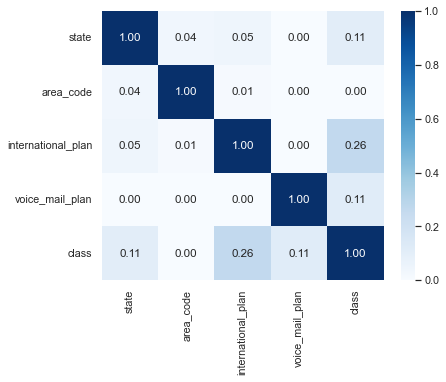

Largest off-diagonal Cramer's V: 0.262
Cramer's V with target: {'state': 0.108, 'area_code': 0.0, 'international_plan': 0.262, 'voice_mail_plan': 0.115}


In [16]:
def cramers_v(a: pd.Series, b: pd.Series) -> float:
    """Bias-corrected Cramer's V."""
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(kc - 1, rc - 1))))


cat_cols = CATS + BINS + [TARGET]
cv = pd.DataFrame(
    [[cramers_v(train[a], train[b]) for b in cat_cols] for a in cat_cols],
    index=cat_cols,
    columns=cat_cols,
)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
plt.show()
print(
    "Largest off-diagonal Cramer's V:", round(cv.where(~np.eye(len(cv), dtype=bool)).max().max(), 3)
)
print("Cramer's V with target:", cv[TARGET].drop(TARGET).round(3).to_dict())

In [17]:
# Interaction look: day minutes x international plan, and day minutes x voicemail
tmp = train.assign(day_bin=pd.qcut(train["total_day_minutes"], 4, labels=["Q1", "Q2", "Q3", "Q4"]))
for c in ["international_plan", "voice_mail_plan"]:
    display(
        tmp.pivot_table(
            index="day_bin", columns=c, values=TARGET, aggfunc="mean", observed=True
        ).round(3)
    )

international_plan,0,1
day_bin,,
Q1,0.093,0.425
Q2,0.065,0.381
Q3,0.042,0.342
Q4,0.253,0.504


voice_mail_plan,0,1
day_bin,,
Q1,0.136,0.081
Q2,0.095,0.100
Q3,0.066,0.058
Q4,0.365,0.060


## 3.5 Segments (train)

,n,churned,rate,ci_low,ci_high
plan_vm,,,,,
intl / no vm,277,124,0.448,0.390,0.507
intl / vm,103,37,0.359,0.273,0.455
no intl / no vm,2662,363,0.136,0.124,0.150
no intl / vm,958,42,0.044,0.033,0.059


,n,churned,rate,ci_low,ci_high
day_tertile,,,,,
low,1333,154,0.116,0.099,0.134
mid,1334,112,0.084,0.070,0.100
high,1333,300,0.225,0.203,0.248


,n,churned,rate,ci_low,ci_high
area_code,,,,,
408,1024,139,0.136,0.116,0.158
415,2016,291,0.144,0.130,0.160
510,960,136,0.142,0.121,0.165


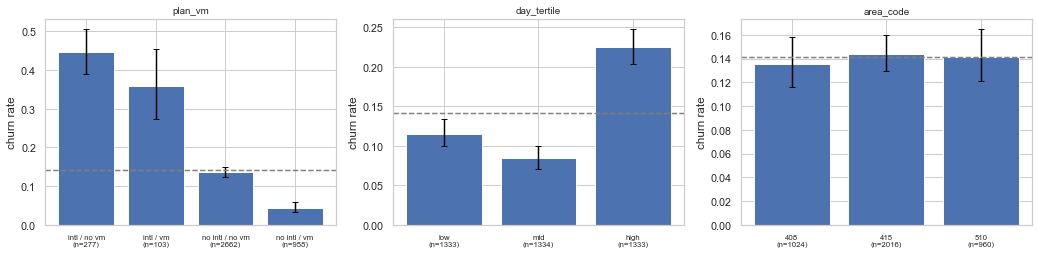

,n,churned,rate,ci_low,ci_high
grp,,,,,
0-3 calls / intl,346,138,0.399,0.349,0.451
0-3 calls / no intl,3336,269,0.081,0.072,0.090
4+ calls / intl,34,23,0.676,0.508,0.809
4+ calls / no intl,284,136,0.479,0.421,0.537


In [18]:
seg = train.assign(
    plan_vm=train["international_plan"].map({0: "no intl", 1: "intl"})
    + " / "
    + train["voice_mail_plan"].map({0: "no vm", 1: "vm"}),
    calls_bucket=np.where(train["number_customer_service_calls"] >= 4, "4+", "0-3"),
    day_tertile=pd.qcut(train["total_day_minutes"], 3, labels=["low", "mid", "high"]),
)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axes, ["plan_vm", "day_tertile", "area_code"], strict=False):
    tab = rate_table(seg, c)
    plot_rate(tab, ax, c)
    display(tab.round(3))
fig.tight_layout()
plt.show()

x = rate_table(
    seg.assign(
        grp=seg["calls_bucket"]
        + " calls / "
        + seg["international_plan"].map({0: "no intl", 1: "intl"})
    ),
    "grp",
)
display(x.round(3))

In [19]:
st = rate_table(train, "state").sort_values("rate", ascending=False)
st["small_sample"] = st["n"] < 60
print("States are anonymous codes; with ~78 customers each, a 51-way ranking is mostly noise.")
display(pd.concat([st.head(6), st.tail(6)]).round(3))
chi2, p = chi2_p(train, "state")
print(f"chi-square state vs churn: chi2={chi2:.1f}, p={p:.3g}")
# Expected spread of the max rate under no state effect (permutation)
rng = np.random.default_rng(0)
n_by = train["state"].value_counts()
sims = []
for _ in range(500):
    y = rng.permutation(train[TARGET].values)
    sims.append(pd.Series(y).groupby(train["state"].values, observed=True).mean().max())
print(
    f"max state rate observed {st['rate'].max():.3f}; under no state effect it is typically "
    f"{np.mean(sims):.3f} (95th pct {np.percentile(sims, 95):.3f})"
)

States are anonymous codes; with ~78 customers each, a 51-way ranking is mostly noise.


,n,churned,rate,ci_low,ci_high,small_sample
state,,,,,,
47,72,21,0.292,0.199,0.405,False
4,41,11,0.268,0.157,0.419,True
31,90,22,0.244,0.167,0.342,False
20,82,19,0.232,0.154,0.334,False
26,75,16,0.213,0.136,0.319,False
43,95,20,0.211,0.141,0.303,False
38,56,4,0.071,0.028,0.170,True
29,72,5,0.069,0.030,0.152,False
45,91,6,0.066,0.031,0.136,False


chi-square state vs churn: chi2=96.5, p=8.78e-05


max state rate observed 0.292; under no state effect it is typically 0.241 (95th pct 0.286)


## Summary of conclusions

In [20]:
intl = rate_table(train, "international_plan")["rate"]
print(f"intl plan churn {intl[1]:.1%} vs {intl[0]:.1%} without")
print(f"4+ service calls churn {high.mean():.1%} vs {low.mean():.1%} for 0-3")
print(f"overall train churn {base:.2%}; no-skill PR-AUC {base:.3f}")

intl plan churn 42.4% vs 11.2% without
4+ service calls churn 50.0% vs 11.1% for 0-3
overall train churn 14.15%; no-skill PR-AUC 0.141


Differences from the strategy doc (train split, 4,000 rows):
- International plan 42.4% vs 11.2% matches. Service calls: 0-3 calls 11.1% (flat), 4 calls 43.7%, 5 calls 57.1%, 6 calls 67.9%;
  the doc's "44-65%" holds for 4-6 calls, 7+ calls have n <= 11 so the rate is not reliable. Pooled 4+ is 50.0%.
- Day usage is not monotone: the top tertile churns at 22.5%, the middle tertile (8.4%) below the bottom (11.6%). The jump is in the top quartile and is concentrated in customers without voicemail (36.5% vs 6.0% with voicemail).
- `state` is significant overall (chi-square p about 9e-5) but the top rate (29.2%) is within the range expected from chance for a 51-way maximum, so rankings are not interpretable.
- `area_code` carries no signal (p = 0.81).

Written conclusions, and what they imply for Steps 2, 5 and 6, are in `reports/eda/findings.md`.